In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras  # type: ignore
from arch import arch_model
from src.utils import evaluate_forecasts

df = pd.read_csv("../data/GSPC_processed.csv", index_col=0, parse_dates=True)
r = df["log_return"]
split = int(len(r) * 0.8)
split_date = r.index[split]

# GJR-GARCH estimated on training data only
am = arch_model(r, mean="Constant", dist="t", vol="GARCH", p=1, o=1, q=1)
res = am.fit(last_obs=r.index[split - 1], disp="off")
gf = res.forecast(horizon=1, start=r.index[0], reindex=False).variance["h.1"]  # made at t, for t+1

feat = pd.DataFrame({
    "ret": r,
    "sq_ret": r ** 2,
    "abs_mean_5d": r.abs().rolling(5).mean(),
    "rv_21d": df["realized_vol_21d"],
    "log_garch_var": np.log(gf),
}).dropna()
garch_var = gf.loc[feat.index]
print("Test starts:", split_date.date())

Test starts: 2023-06-06


In [2]:
train_rows = feat.index < split_date
mu, sd = feat[train_rows].mean(), feat[train_rows].std()
feat_s = ((feat - mu) / sd).clip(-5, 5)          # clip tames extreme outliers

LOOK = 22
vals, idx = feat_s.values, feat_s.index
rsq = (r ** 2).loc[idx].values
gv = garch_var.values

X, y, g, dates = [], [], [], []
for t in range(LOOK, len(idx)):
    X.append(vals[t - LOOK:t])      # features up to day t-1
    y.append(rsq[t])                # target: squared return on day t
    g.append(gv[t - 1])             # GJR-GARCH forecast for day t, made on day t-1
    dates.append(idx[t])
X, y, g, dates = np.array(X), np.array(y), np.array(g), pd.DatetimeIndex(dates)

train_mask = dates < split_date
test_dates = dates[~train_mask]
const_var = (r ** 2)[r.index < split_date].mean()   # unconditional variance, baseline for the pure LSTM

def make_sets(X_, base):
    Y = np.column_stack([y, base])                   # column 0: target, column 1: baseline variance
    Xa, Ya = X_[train_mask], Y[train_mask]
    v = int(len(Xa) * 0.9)                           # last 10% of training = validation
    return dict(X_tr=Xa[:v], Y_tr=Ya[:v], X_val=Xa[v:], Y_val=Ya[v:],
                X_te=X_[~train_mask], Y_te=Y[~train_mask])

sets = {
    "Hybrid (QLIKE)": make_sets(X, g),                                  # sees GARCH, multiplies its forecast
    "LSTM (QLIKE)":   make_sets(X[:, :, :4], np.full(len(y), const_var)),  # no GARCH inputs
}

# Sanity check: baseline should match the saved GJR-GARCH (fixed) forecasts from notebook 03
saved = pd.read_csv("../data/garch_forecasts.csv", index_col=0, parse_dates=True)["GJR-GARCH"]
mine = pd.Series(sets["Hybrid (QLIKE)"]["Y_te"][:, 1], index=test_dates)
print("Max difference vs notebook 03 GJR-GARCH:", float((mine - saved.reindex(test_dates)).abs().max()))

Max difference vs notebook 03 GJR-GARCH: 8.881784197001252e-16


In [3]:
def qlike_loss(y_true, y_pred):
    y_ = y_true[:, 0:1]                       # realized-variance proxy
    base = y_true[:, 1:2]                     # baseline variance forecast
    out = tf.clip_by_value(y_pred, -4.0, 4.0) # log-multiplier
    f = base * tf.exp(out)                    # forecast variance
    return tf.reduce_mean(tf.math.log(f) + y_ / f)

def build_model(n_feat, lr=3e-4):
    m = keras.Sequential([
        keras.layers.Input(shape=(LOOK, n_feat)),
        keras.layers.LSTM(16),
        keras.layers.Dropout(0.2),
        # zero init: multiplier starts at exp(0) = 1, i.e. exactly the baseline forecast
        keras.layers.Dense(1, kernel_initializer="zeros", bias_initializer="zeros"),
    ])
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=qlike_loss)
    return m

def train_ensemble(s, n_seeds=5):
    preds, histories = [], []
    for seed in range(n_seeds):
        np.random.seed(seed); tf.random.set_seed(seed)
        m = build_model(s["X_tr"].shape[2])
        early = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)
        h = m.fit(s["X_tr"], s["Y_tr"], validation_data=(s["X_val"], s["Y_val"]),
                  epochs=200, batch_size=64, callbacks=[early], verbose=0)
        out = np.clip(m.predict(s["X_te"], verbose=0).ravel(), -4, 4)
        preds.append(s["Y_te"][:, 1] * np.exp(out))
        histories.append(h.history)
        print(f"  seed {seed}: stopped after {len(h.history['loss'])} epochs, "
              f"best val loss {min(h.history['val_loss']):.4f}")
    return np.array(preds).T, histories      # shape (n_test, n_seeds)

In [4]:
results = {}
for name, s in sets.items():
    print(name)
    results[name] = train_ensemble(s, n_seeds=5)

Hybrid (QLIKE)
  seed 0: stopped after 125 epochs, best val loss 1.5787
  seed 1: stopped after 73 epochs, best val loss 1.5799
  seed 2: stopped after 120 epochs, best val loss 1.5765
  seed 3: stopped after 16 epochs, best val loss 1.6143
  seed 4: stopped after 58 epochs, best val loss 1.5846
LSTM (QLIKE)
  seed 0: stopped after 30 epochs, best val loss 1.5706
  seed 1: stopped after 30 epochs, best val loss 1.5683
  seed 2: stopped after 36 epochs, best val loss 1.5728
  seed 3: stopped after 31 epochs, best val loss 1.5703
  seed 4: stopped after 28 epochs, best val loss 1.5760


In [5]:
from src.utils import qlike

saved_gjr = pd.read_csv("../data/garch_forecasts.csv", index_col=0, parse_dates=True)[["GJR-GARCH"]]
old_lstm = pd.read_csv("../data/lstm_forecasts.csv", index_col=0, parse_dates=True)["LSTM"].rename("LSTM (old)")
old_hyb = pd.read_csv("../data/hybrid_forecasts.csv", index_col=0, parse_dates=True).iloc[:, 0].rename("Hybrid (old)")

fc = saved_gjr.copy()
for name, (preds, _) in results.items():
    fc = fc.join(pd.Series(preds.mean(axis=1), index=test_dates, name=name + " ensemble"), how="inner")
fc = fc.join(old_lstm, how="inner").join(old_hyb, how="inner").dropna()
proxy = r.loc[fc.index] ** 2
display(evaluate_forecasts(proxy, fc).round(4))

# QLIKE of each individual seed, to show run-to-run variation
for name, (preds, _) in results.items():
    pr = r.loc[test_dates] ** 2
    q = [qlike(pr, preds[:, k]) for k in range(preds.shape[1])]
    print(f"{name}: per-seed QLIKE mean {np.mean(q):.4f}, sd {np.std(q):.4f}, "
          f"min {np.min(q):.4f}, max {np.max(q):.4f}")

,RMSE,MAE,QLIKE
Hybrid (QLIKE) ensemble,3.1081,0.9021,0.5546
LSTM (QLIKE) ensemble,3.3094,0.8659,0.5687
GJR-GARCH,3.1085,0.9430,0.5829
Hybrid (old),3.3299,0.8974,0.5967
LSTM (old),3.3102,0.9352,0.6028


Hybrid (QLIKE): per-seed QLIKE mean 0.5655, sd 0.0093, min 0.5535, max 0.5822
LSTM (QLIKE): per-seed QLIKE mean 0.5709, sd 0.0118, min 0.5488, max 0.5813


In [6]:
import statsmodels.api as sm

def dm_test(proxy, fa, fb, lags=5):
    fa, fb = fa.clip(lower=1e-8), fb.clip(lower=1e-8)
    d = ((np.log(fa) + proxy / fa) - (np.log(fb) + proxy / fb)).values
    out = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return out.tvalues[0], out.pvalues[0]

pairs = [("Hybrid (QLIKE) ensemble", "GJR-GARCH"),
         ("LSTM (QLIKE) ensemble", "GJR-GARCH"),
         ("Hybrid (QLIKE) ensemble", "LSTM (QLIKE) ensemble"),
         ("LSTM (QLIKE) ensemble", "LSTM (old)"),
         ("Hybrid (QLIKE) ensemble", "Hybrid (old)")]
for a, b in pairs:
    s_, p_ = dm_test(proxy, fc[a], fc[b])
    print(f"{a} vs {b}: DM = {s_:.2f}, p = {p_:.3f}   (negative = first has lower loss)")

Hybrid (QLIKE) ensemble vs GJR-GARCH: DM = -2.06, p = 0.040   (negative = first has lower loss)
LSTM (QLIKE) ensemble vs GJR-GARCH: DM = -0.42, p = 0.676   (negative = first has lower loss)
Hybrid (QLIKE) ensemble vs LSTM (QLIKE) ensemble: DM = -0.49, p = 0.624   (negative = first has lower loss)
LSTM (QLIKE) ensemble vs LSTM (old): DM = -3.47, p = 0.001   (negative = first has lower loss)
Hybrid (QLIKE) ensemble vs Hybrid (old): DM = -1.22, p = 0.221   (negative = first has lower loss)


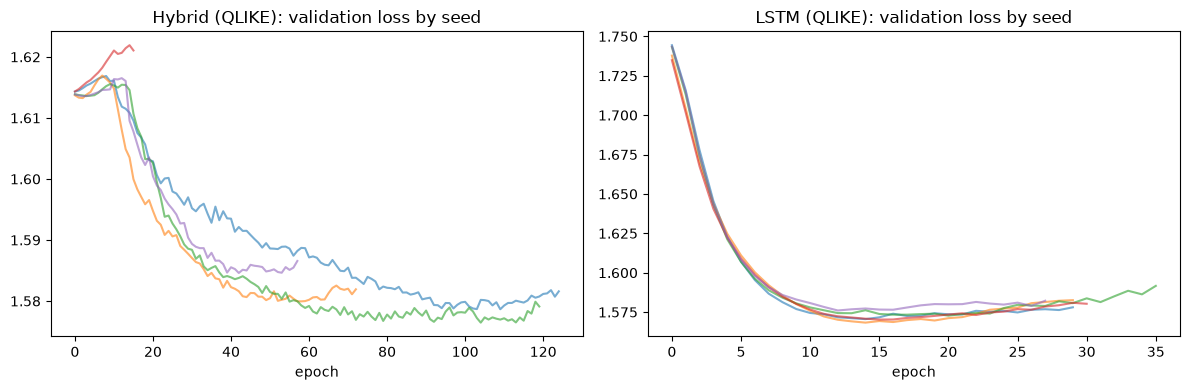

In [7]:
for name, (preds, _) in results.items():
    pd.Series(preds.mean(axis=1), index=test_dates, name=name).to_csv(
        "../data/" + name.split(" ")[0].lower() + "_qlike_forecasts.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, (name, (_, hists)) in zip(ax, results.items()):
    for h in hists:
        a_.plot(h["val_loss"], alpha=0.6)
    a_.set_title(f"{name}: validation loss by seed"); a_.set_xlabel("epoch")
plt.tight_layout(); plt.show()